# TestBrain

Notebook de training pour les modèles CNN, ResNet et ViT, avec une visualisation finale des images du test set et de leurs labels.

In [1]:
# ruff: noqa: E402
import os
import random
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore", category=UserWarning, module="keras")

import numpy as np
import tensorflow as tf
from keras.optimizers import Adam, AdamW
from matplotlib import pyplot as plt

from models.CNN import CNN
from models.ResNet import ResNet
from models.ViT import ViT
from utils import SIZE, Dataset

I0000 00:00:1794444228.523667  204221 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794444231.907585  204221 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
dataset = Dataset("dataset2")
X_train, y_train = dataset.train
X_test, y_test = dataset.test

models = [
    CNN(dataset.num_classes),
    ResNet(dataset.num_classes),
    ViT(dataset.num_classes),
]

colors = [
    ("blue", "cornflowerblue"),
    ("darkorange", "moccasin"),
    ("purple", "violet"),
]

print("Classes :", dataset.mapping)
print(f"Train : {len(X_train)} images | Test : {len(X_test)} images")

Classes : {0: 'glioma', 1: 'notumor', 2: 'meningioma', 3: 'pituitary'}
Train : 5600 images | Test : 1600 images


CNN    | epochs: 50 | best val_acc: 0.8857 | best val_loss: 0.3058
ResNet | epochs: 43 | best val_acc: 0.9446 | best val_loss: 0.1960
ViT    | epochs: 50 | best val_acc: 0.8580 | best val_loss: 0.3670


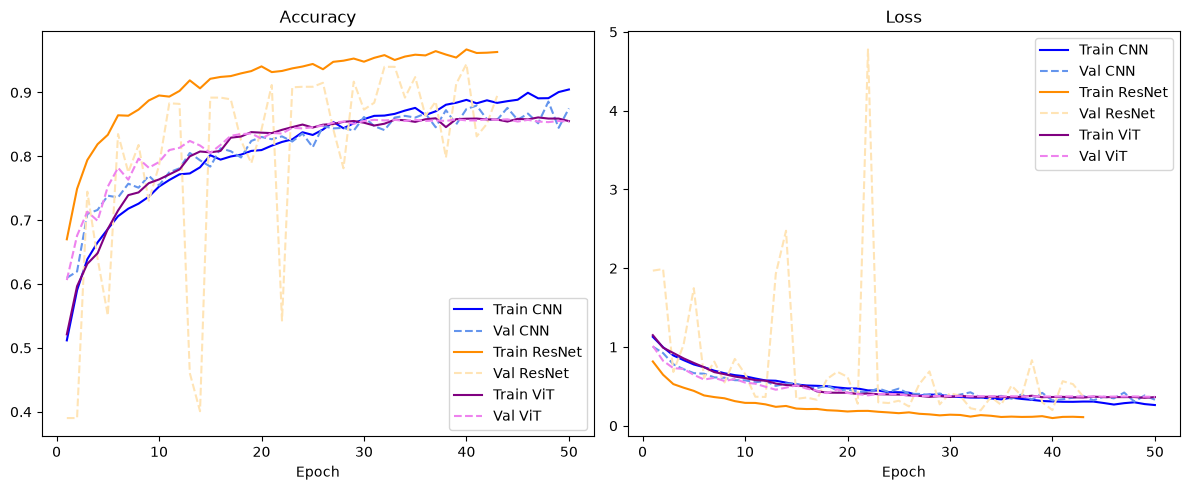

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.set_title("Accuracy")
ax1.set_xlabel("Epoch")
ax2.set_title("Loss")
ax2.set_xlabel("Epoch")

for model, (main_color, second_color) in zip(models, colors):
    model(np.zeros((1, SIZE, SIZE, 1)))

    optimizer = (
        AdamW(learning_rate=1e-4, weight_decay=1e-4) if model.name == "ViT" else Adam()
    )

    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=optimizer,
        metrics=["accuracy"],
    )

    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6,
    )
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=32,
        validation_split=0.2,
        callbacks=[reduce_lr, early_stop] if model.name == "ViT" else [early_stop],
        verbose=0,
    )

    best_val_acc = max(history.history["val_accuracy"])
    best_val_loss = min(history.history["val_loss"])
    epochs_run = len(history.history["loss"])
    print(
        f"{model.name:<6} | epochs: {epochs_run:>2} "
        f"| best val_acc: {best_val_acc:.4f} | best val_loss: {best_val_loss:.4f}"
    )

    epoch_list = list(range(1, epochs_run + 1))
    ax1.plot(
        epoch_list,
        history.history["accuracy"],
        label=f"Train {model.name}",
        color=main_color,
    )
    ax2.plot(
        epoch_list,
        history.history["loss"],
        label=f"Train {model.name}",
        color=main_color,
    )
    ax1.plot(
        epoch_list,
        history.history["val_accuracy"],
        linestyle="--",
        label=f"Val {model.name}",
        color=second_color,
    )
    ax2.plot(
        epoch_list,
        history.history["val_loss"],
        linestyle="--",
        label=f"Val {model.name}",
        color=second_color,
    )

ax1.legend()
ax2.legend()
plt.tight_layout()
plt.show()

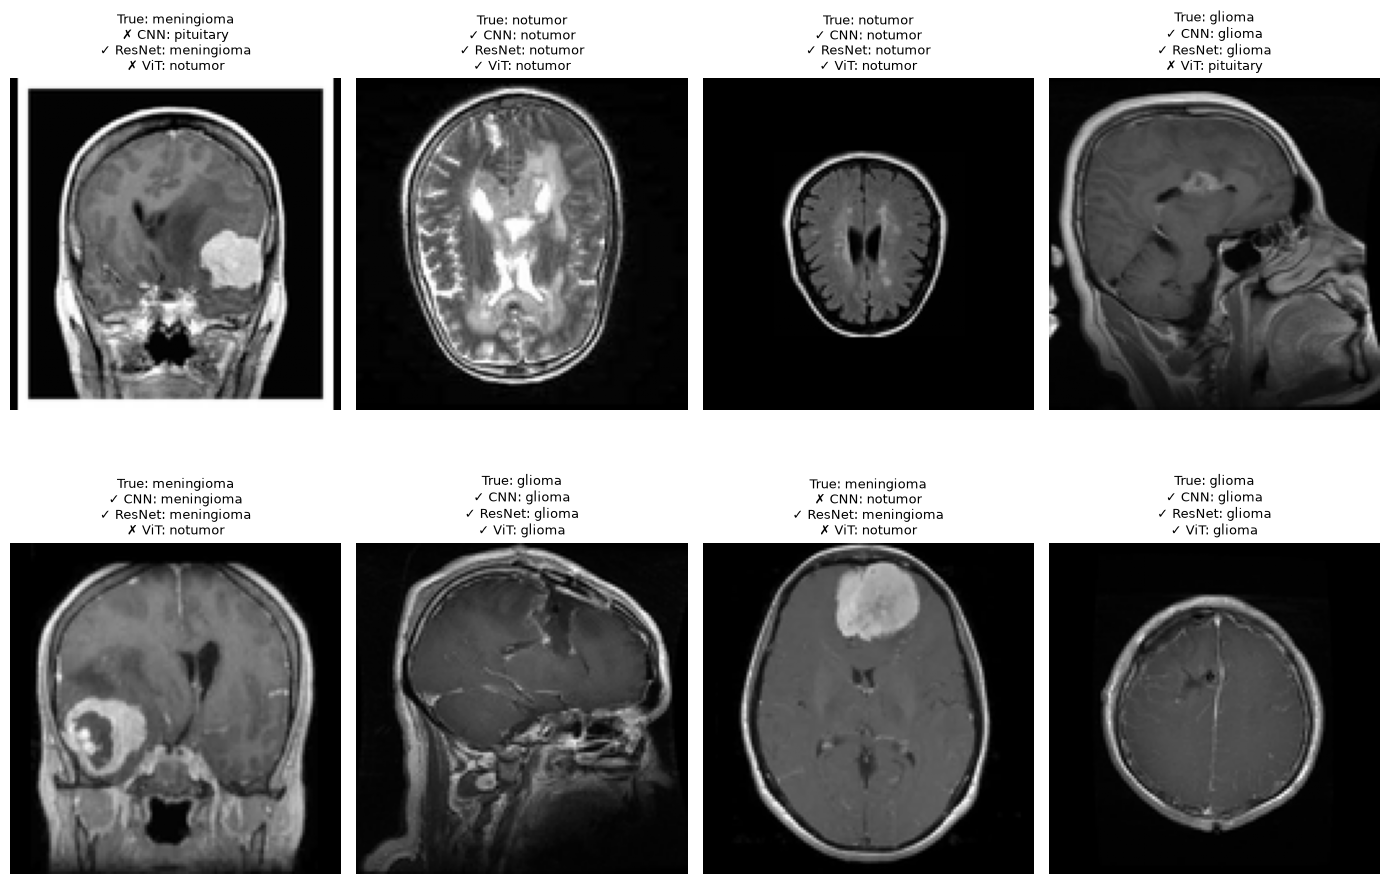

In [17]:
max_brains = 8
idx = random.sample(range(len(X_test)), 8)
imgs = X_test[idx]
preds = {m.name: m.predict(imgs, verbose=0).argmax(axis=1) for m in models}

fig, axes = plt.subplots(2, 4, figsize=(14, 10))
for k, (i, ax) in enumerate(zip(idx, axes.flat)):
    actual = dataset.mapping[y_test[i]]
    lines = [f"True: {actual}"] + [
        f"{'✓' if (p := dataset.mapping[y_pred[k]]) == actual else '✗'} {name}: {p}"
        for name, y_pred in preds.items()
    ]
    ax.imshow(dataset.reverse_transform(imgs[k]), cmap="gray")
    ax.set_title("\n".join(lines), fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.savefig("image.png", bbox_inches="tight")
plt.show()


In [5]:
from sklearn.metrics import classification_report

results = {}
for model in models:
    preds = model.predict(X_test, verbose=0)
    pred_idx = preds.argmax(axis=1)
    acc = float((pred_idx == y_test).mean())
    results[model.name] = acc

sorted_results = sorted(results.items(), key=lambda x: x[1], reverse=True)
print("Test set accuracies:")
for name, acc in sorted_results:
    print(f"- {name}: {acc:.4f}")

ranking = " > ".join([name for name, _ in sorted_results])
print("\nRanking:", ranking)

# Optionnel : classification report for best model
best_name = sorted_results[0][0]
best_model = next(m for m in models if m.name == best_name)
best_preds = best_model.predict(X_test, verbose=0).argmax(axis=1)
print("\nClassification report (best model):")
print(classification_report(y_test, best_preds))

Test set accuracies:
- ResNet: 0.8969
- CNN: 0.8194
- ViT: 0.7756

Ranking: ResNet > CNN > ViT

Classification report (best model):
              precision    recall  f1-score   support

           0       0.98      0.74      0.84       400
           1       0.86      1.00      0.92       400
           2       0.86      0.87      0.87       400
           3       0.91      0.98      0.94       400

    accuracy                           0.90      1600
   macro avg       0.90      0.90      0.89      1600
weighted avg       0.90      0.90      0.89      1600

